# Companion notebook to "Only Getting the Eigenvalues You Really Want: the Davidson method"

Containing example for the power iteration and Davidson method.

In [81]:
# Imports & others
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

from IPython.display import HTML

## The power iteration

An almost one-to-one implementation of the pseudocode is:

In [75]:
def rayleigh_coefficient(A: np.ndarray, v: np.ndarray) -> np.ndarray:
    """Compute the Rayleigh coefficient $R(A,v)$"""
    return v.T @ A @ v / (v.T @ v)

def power_iteration(A: np.ndarray, epsilon: float = 1e-5) -> tuple[float, list[np.ndarray]]:
    """Get the eigenvalue (with the largest abslute value) of `A`, and its corresponding eigenvector"""
    n = A.shape[0]
    b_k = np.random.rand(n)
    lambda_k = rayleigh_coefficient(A, b_k)
    vectors = [b_k]  # to keep track of vectors for visualization
    while np.linalg.norm(A @ b_k - lambda_k * b_k) > epsilon:
        b_k = A @ b_k / np.linalg.norm(A @ b_k)
        if np.isclose(np.linalg.norm(b_k), 0):
            raise Exception('b_k is zero')
        lambda_k = rayleigh_coefficient(A, b_k)
        vectors.append(b_k)
    return lambda_k, vectors

# Let's use that (matrix must be Hermitian to avoid complexes)
A = np.array([
    [1.5, .1, .3],
    [.1, -2, .2],
    [.3, .2, -1],
])
eigenvalue, eigenvectors = power_iteration(A)
print(f'The largest eigenvalue is {eigenvalue}, '
    f'corresponding to an eigenvector of {eigenvectors[-1]}, '
    f'obtained in {len(eigenvectors)} iteration(s)')

The largest eigenvalue is -2.03901512014881, corresponding to an eigenvector of [ 0.01202749 -0.9825409   0.18565753], obtained in 48 iteration(s)


Let's visualize this:

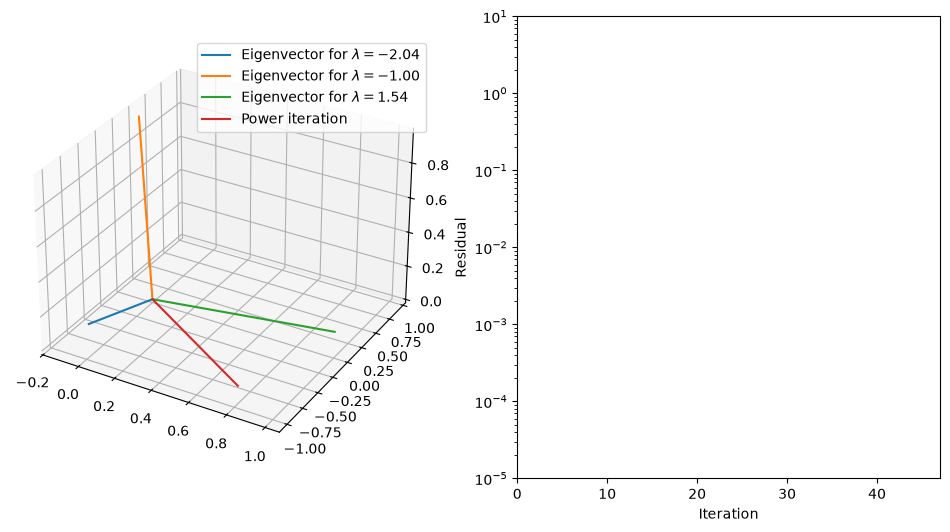

In [82]:
true_eigv, true_eigf = np.linalg.eigh(A)

fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(1, 2, 1, projection='3d')

for e, v in zip(true_eigv, true_eigf.T):
    ax.plot([0, v[0]], [0, v[1]], [0, v[2]], label=f'Eigenvector for $\\lambda={e:.2f}$')

b_k_plot = ax.plot([0, eigenvectors[0][0]], [0, eigenvectors[0][1]], [0, eigenvectors[0][2]], label='Power iteration')[0]

ax.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.set_xlim(0, len(eigenvectors) - 1)
ax2.set_ylim(1e-5, 1e1)
ax2.set_ylabel('Residual')
ax2.set_xlabel('Iteration')

eigf_plot = ax2.semilogy([0], [np.linalg.norm(eigenvectors[-1] - eigenvectors[0])], 'o-')[0]

def update(frame):
    b_k_plot.set_xdata([0, eigenvectors[frame + 1][0]])
    b_k_plot.set_ydata([0, eigenvectors[frame + 1][1]])
    b_k_plot.set_3d_properties([0, eigenvectors[frame + 1][2]])
    
    eigf_plot.set_xdata(list(range(frame)))
    eigf_plot.set_ydata(list(np.linalg.norm(A @ v - rayleigh_coefficient(A, v) * v) for v in eigenvectors[:frame]))
    return b_k_plot

ani = animation.FuncAnimation(fig=fig, func=update, frames=len(eigenvectors) - 1, interval=500)
HTML(ani.to_html5_video())

## The Davidson method

Let's first create a function to compute $N$ eigenpairs with the Davidson method.
This code is a fair translation of the pseudo-code.

Technicalites:

1. we use a function `AQ(Q)` which computes $\mathbf A\mathbf Q$ (in order to be matrix free if needed), and we also need to provide `D=diag(A)`,
2. we use a random subspace as a starting point, we could obviously do better,
3. we need to avoid division by zero if $D_{jj}-\theta_i \approx 0$ (this happens if $\mathbf A$ is very strongly diagonal, $\forall i\neq j: A_{ij}\approx 0$), and
4. we need to ortogonalize $\mathbf t_i$ carefully so that $\mathbf Q^\dagger\mathbf Q = 0$. Here, I "just" use two loops of Gram-Shmidt.

In [70]:
def eig_davidson(AQ, D, n: int, N: int, K: int = 100, epsilon: float = 1e-5) -> tuple[np.ndarray, np.ndarray]:
    Q, _ = np.linalg.qr(np.random.randn(n, N))  # using random subspace
    for i in range(K):
        sigma_A = AQ(Q)
        H = Q.T @ sigma_A
        eigenvalues, eigenvectors = np.linalg.eigh(H)
        ritz_values = eigenvalues[:N]
        ritz_vectors = Q @ eigenvectors[:, :N]
        corrections = []
        c = 0
        largest_residual = 0
        for j in range(N):
            theta_j = ritz_values[j]
            u_j = ritz_vectors[:, j]
            r_j = sigma_A @ eigenvectors[:, j] - theta_j * u_j
            largest_residual = np.max([largest_residual, np.linalg.norm(r_j)])
            if np.linalg.norm(r_j) < epsilon:
                c += 1
                continue
            denominator = D - theta_j
            threshold = 1e-8
            small = np.abs(denominator) < threshold
            denominator[small] = np.where(denominator[small] >= 0, threshold, -threshold)
            t_j = -r_j / denominator
            for _ in range(2):
                t_j -= Q @ (Q.T @ t_j)
                if corrections:
                    T = np.column_stack(corrections)
                    t_j -= T @ (T.T @ t_j)
            norm_t = np.linalg.norm(t_j)
            if norm_t > 1e-12:
                corrections.append(t_j / norm_t)
        if c == N:
            print(f'All eigenpairs obtained in {i+1} iteration(s), largest_residual={largest_residual:.3e}')
            return ritz_values, ritz_vectors.T
        if not corrections:
            break
        Q = np.column_stack((Q, *corrections))
        print(f'iter={i+1}, {N-c} non-converged eigenpair(s), largest_residual={largest_residual:.3e}, subspace size={Q.shape[1]}')
    raise RuntimeError(
        f"Davidson did not converge within {K} iterations. "
        f"Converged eigenpairs: {c}/{N}."
    )

# let's try it:
A = np.array([
    [1.5, .1, .3],
    [.1, -2, .2],
    [.3, .2, -1],
])

print(eig_davidson(lambda Q: A @ Q, np.diagonal(A), 3, 1))

iter=1, 1 non-converged eigenpair(s), largest_residual=1.055e+00, subspace size=2
iter=2, 1 non-converged eigenpair(s), largest_residual=1.096e+00, subspace size=3
All eigenpairs obtained in 3 iteration(s), largest_residual=1.286e-15
(array([-2.03901512]), array([[-0.01202508,  0.98254099, -0.18565723]]))


This time, we obtain the lowest eigenvalue (and its corresponding eigenvector) matching the result above, but in only **2** iterations.

### An example

Let's consider a particle in a one-dimensional periodic potential over a length $L$, with periodic boundary conditions and $G_0 = \frac{2\pi}{L}$. The Hamiltonian is

$$
\hat H = -\frac{1}{2}\frac{d^2}{dx^2} + V(x), \qquad V(x) = V_0\cos(G_0x) = \frac{V_0}{2}\left(e^{iG_0x}+e^{-iG_0x}\right),
$$

where we use atomic units ($\hbar=m=1$).
We represent the wavefunction in a plane-wave basis:

$$
\psi_n(x) = \frac{1}{\sqrt L}e^{inG_0x}, \qquad n\in\mathbb Z.
$$

These basis functions are orthonormal:

$$
\langle\psi_k|\psi_l\rangle = \int_0^L \psi_k^*(x)\psi_l(x)\,dx = \delta_{kl}.
$$

The Hamiltonian matrix elements are therefore

$$
\begin{aligned}
H_{kl} &= \langle\psi_k|\hat H|\psi_l\rangle \\
&= \int_0^L \psi_k^*(x)\hat H\psi_l(x)\,dx \\
&= \frac{k^2G_0^2}{2}\delta_{kl} + \frac{V_0}{2}\left(\delta_{k,l-1}+\delta_{k,l+1}\right).
\end{aligned}
$$

The resulting eigenvalue problem is

$$
\mathbf H\mathbf C = \mathbf C\boldsymbol{\varepsilon},
$$

where the columns of $\mathbf C$ contain the eigenvectors and $\boldsymbol{\varepsilon}$ is the diagonal matrix of eigenvalues.
The Hamiltonian is tridiagonal. For example, using the five plane waves with $n\in[-2,2]$, we obtain

$$
\mathbf H =
\begin{pmatrix}
2G_0^2 & V_0/2 & 0 & 0 & 0\\
V_0/2 & G_0^2/2 & V_0/2 & 0 & 0\\
0 & V_0/2 & 0 & V_0/2 & 0\\
0 & 0 & V_0/2 & G_0^2/2 & V_0/2\\
0 & 0 & 0 & V_0/2 & 2G_0^2
\end{pmatrix}.
$$

The matrix is very sparse, it easy to go **matrix-free**!
So, let's do that:

In [88]:
Nbas = 200  # size of the basis
L = 5
G0 = 2 * np.pi / L
V_0 = 5

print(f'Matrix is {2*Nbas+1}x{2*Nbas+1}, cutoff energy is {Nbas ** 2 * G0**2 / 2}')

def HQ(Q):
    """Compute H @ Q without explicitly constructing H."""
    n = np.arange(-Nbas, Nbas + 1)
    result = (0.5 * (n * G0)**2)[:, None] * Q  # kinetic contribution
    result[1:, :] += 0.5 * V_0 * Q[:-1, :] # potential V_0
    result[:-1, :] += 0.5 * V_0 * Q[1:, :] # potential V_0
    return result

print('-' * 80)
K = 15  # number of eigenpairs
eigv, eigf = eig_davidson(HQ, .5 * (np.arange(-Nbas, Nbas + 1) * G0)**2, 2 * Nbas + 1, K)
print('-' * 80)

for i in range(1, K):
    n = (i + 1)  // 2
    if i % 2 == 0:
        n *= -1
    print(f'n={n:3}, E_n = {eigv[i]:.5e}, E\'_n = {n ** 2 * G0 ** 2 / 2:.5e}')

Matrix is 401x401, cutoff energy is 31582.734083485942
--------------------------------------------------------------------------------
iter=1, 15 non-converged eigenpair(s), largest_residual=1.022e+04, subspace size=30
iter=2, 15 non-converged eigenpair(s), largest_residual=8.883e+03, subspace size=45
iter=3, 15 non-converged eigenpair(s), largest_residual=8.125e+03, subspace size=60
iter=4, 15 non-converged eigenpair(s), largest_residual=5.786e+03, subspace size=75
iter=5, 15 non-converged eigenpair(s), largest_residual=4.229e+03, subspace size=90
iter=6, 15 non-converged eigenpair(s), largest_residual=3.908e+03, subspace size=105
iter=7, 15 non-converged eigenpair(s), largest_residual=3.908e+03, subspace size=120
iter=8, 15 non-converged eigenpair(s), largest_residual=3.507e+03, subspace size=135
iter=9, 15 non-converged eigenpair(s), largest_residual=3.341e+03, subspace size=150
iter=10, 15 non-converged eigenpair(s), largest_residual=4.057e+03, subspace size=165
iter=11, 15 non-co

We could check w.r.t. direct diagonalization (`np.linalg.eig(A)` or so), but it actually gives the correct eigenvalues, trust me on that ;)

In the special case $V_0=0$, the Hamiltonian becomes diagonal, and we recover the free-particle energy spectrum with periodic boundary conditions:

$$
E'_n = \frac{n^2G_0^2}{2}, \qquad n\in\mathbb Z.
$$

We can check that using $V_0\to 0$. Indeed, Davidson approach struggles with diagonal matrices ($V_0 = 0$), but it is an easy case to deal with if any.